# Klasifikasi Citra AI-Generated dan Citra Asli
## Menggunakan Vision Transformer (ViT-Base/16)

**Dataset:** AI Generated Images vs Real Images (140K Real and Fake Faces Dataset)  
**Model:** ViT-Base/16 dengan Transfer Learning dari ImageNet-21k
**Baselines:** ResNet-50, EfficientNet-B0 
**Framework:** PyTorch + timm

---
### Struktur Notebook
1. Setup & Instalasi
2. Upload & Ekstraksi Dataset
3. Eksplorasi Data (EDA)
4. Preprocessing & Augmentasi
5. Inisialisasi Model ViT
6. Konfigurasi Hyperparameter dan Pelatihan Model
7. Evaluasi Model (Accuracy, Precision, Recall, F1, AUC-ROC, Confusion Matrix)
8. Baseline Comparison (ResNet-50, EfficientNet-B0)
9. Robustness Testing (JPEG Compression, Resolusi, Noise)
10. Visualisasi Attention Rollout
11. Ringkasan Akhir

## 1. Setup & Instalasi

In [1]:
# Install library tambahan yang dibutuhkan
!pip install timm -q

import os
import random
import shutil
import zipfile
import io
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image, ImageFilter
from tqdm.notebook import tqdm
from collections import defaultdict

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Seed untuk reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

# Device
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB')

Device: cuda
GPU: Tesla T4
Memory: 15.64 GB


## 2. Ekstraksi Dataset

In [2]:
# Struktur dataset 140k: real_vs_fake/train/real & real_vs_fake/train/fake
BASE_DIR = '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake'


AI_DIR   = os.path.join(BASE_DIR, 'train', 'fake')
REAL_DIR = os.path.join(BASE_DIR, 'train', 'real')

print(f'AI-Generated  : {AI_DIR}')
print(f'Real Images   : {REAL_DIR}')
print(f'Jumlah AI     : {len(os.listdir(AI_DIR))} gambar')
print(f'Jumlah Real   : {len(os.listdir(REAL_DIR))} gambar')

AI-Generated  : /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/train/fake
Real Images   : /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/train/real
Jumlah AI     : 50000 gambar
Jumlah Real   : 50000 gambar


## 3. Eksplorasi Data (EDA)

In [3]:
# Kumpulkan semua path dan label — dengan subset 7500 per kelas
import random

all_ai_paths   = [os.path.join(AI_DIR, f) for f in os.listdir(AI_DIR)
                  if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
all_real_paths = [os.path.join(REAL_DIR, f) for f in os.listdir(REAL_DIR)
                  if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

# Subset 7500 per kelas agar RAM aman
random.seed(SEED)
ai_sampled   = random.sample(all_ai_paths,   min(7500, len(all_ai_paths)))
real_sampled = random.sample(all_real_paths, min(7500, len(all_real_paths)))

all_paths  = np.array(ai_sampled + real_sampled)
all_labels = np.array([1]*len(ai_sampled) + [0]*len(real_sampled))

n_ai   = np.sum(all_labels == 1)
n_real = np.sum(all_labels == 0)
total  = len(all_labels)
print(f'Total dataset  : {total} gambar')
print(f'AI-Generated   : {n_ai} ({n_ai/total*100:.1f}%)')
print(f'Real Images    : {n_real} ({n_real/total*100:.1f}%)')

Total dataset  : 15000 gambar
AI-Generated   : 7500 (50.0%)
Real Images    : 7500 (50.0%)


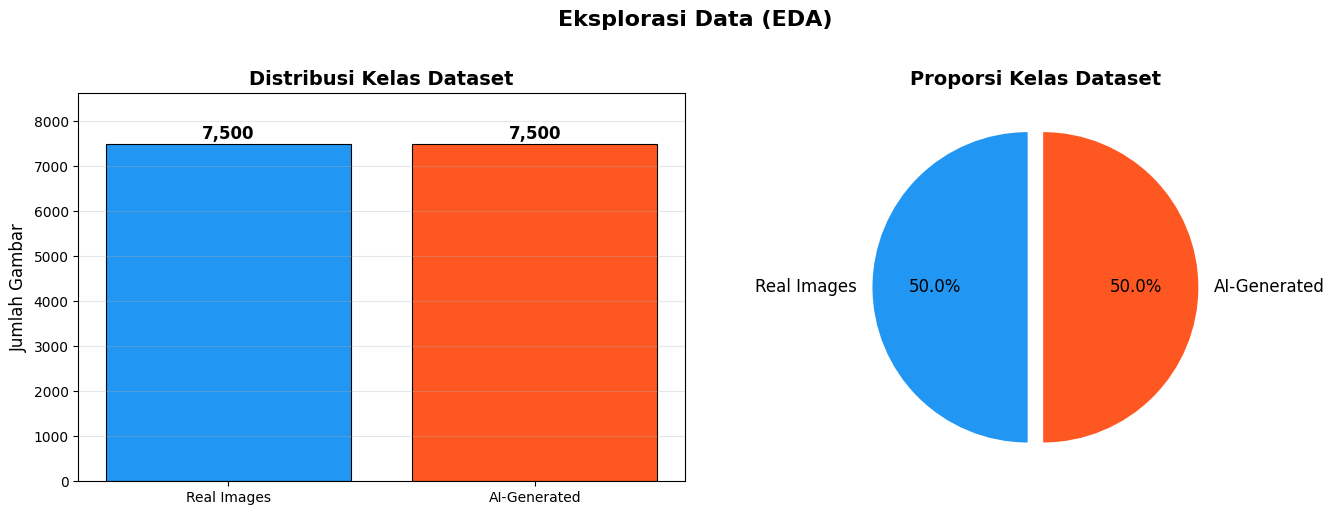

In [4]:
# Visualisasi distribusi kelas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
bars = axes[0].bar(['Real Images', 'AI-Generated'], [n_real, n_ai],
                   color=['#2196F3', '#FF5722'], edgecolor='black', linewidth=0.8)
axes[0].set_title('Distribusi Kelas Dataset', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Jumlah Gambar', fontsize=12)
for bar, val in zip(bars, [n_real, n_ai]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'{val:,}', ha='center', va='bottom', fontsize=12, fontweight='bold')
axes[0].set_ylim(0, max(n_real, n_ai) * 1.15)
axes[0].grid(axis='y', alpha=0.3)

# Pie chart
axes[1].pie([n_real, n_ai], labels=['Real Images', 'AI-Generated'],
            autopct='%1.1f%%', colors=['#2196F3', '#FF5722'],
            startangle=90, explode=(0.05, 0.05),
            textprops={'fontsize': 12})
axes[1].set_title('Proporsi Kelas Dataset', fontsize=14, fontweight='bold')

plt.suptitle('Eksplorasi Data (EDA)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/kaggle/working/eda_distribusi.png', dpi=150, bbox_inches='tight')
plt.show()

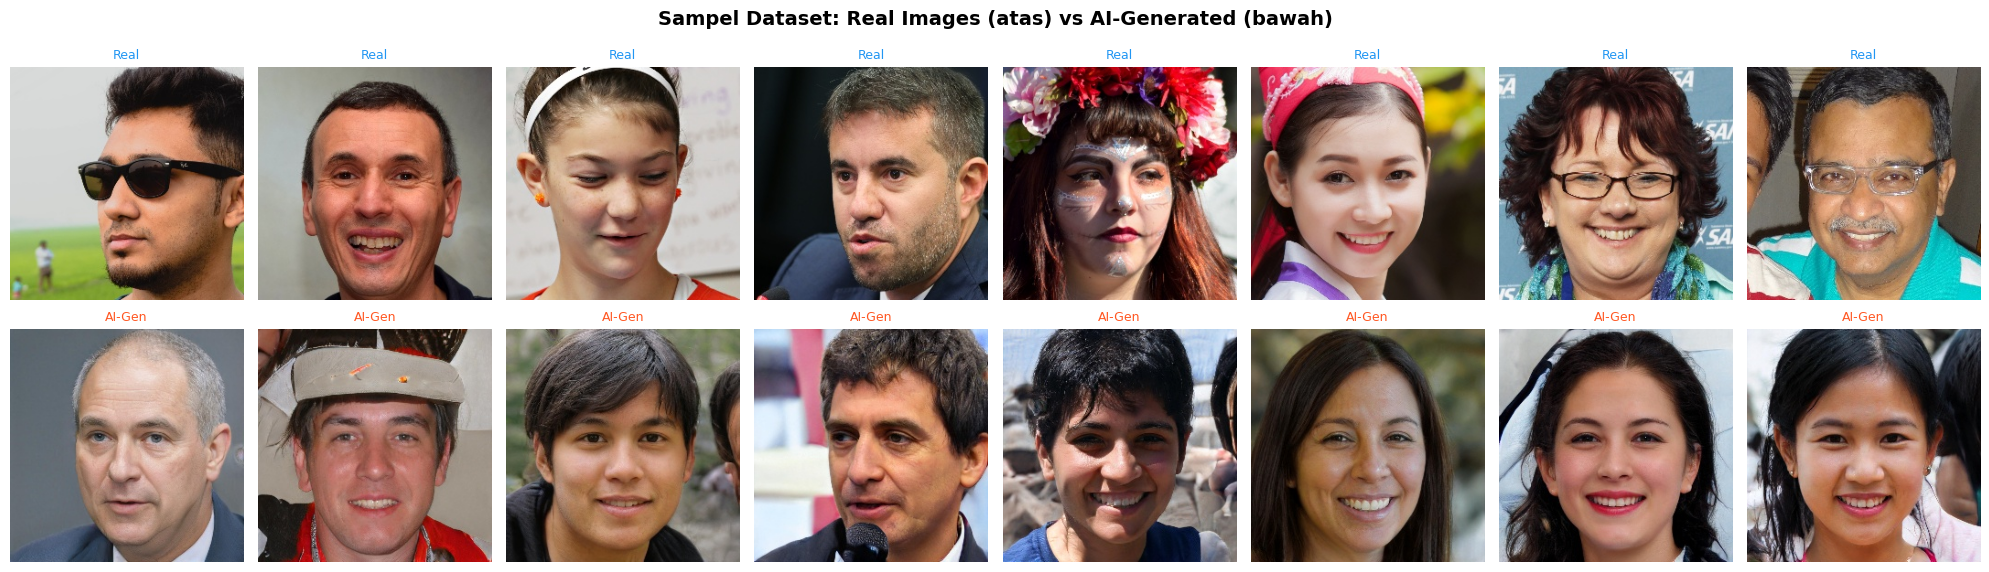

In [5]:
# Tampilkan sampel gambar dari kedua kelas
fig, axes = plt.subplots(2, 8, figsize=(20, 6))
fig.suptitle('Sampel Dataset: Real Images (atas) vs AI-Generated (bawah)',
             fontsize=14, fontweight='bold')

real_paths = all_paths[all_labels == 0]
ai_paths   = all_paths[all_labels == 1]

sample_real = random.sample(list(real_paths), 8)
sample_ai   = random.sample(list(ai_paths), 8)

for i, path in enumerate(sample_real):
    img = Image.open(path).convert('RGB')
    axes[0, i].imshow(img)
    axes[0, i].axis('off')
    axes[0, i].set_title('Real', fontsize=9, color='#2196F3')

for i, path in enumerate(sample_ai):
    img = Image.open(path).convert('RGB')
    axes[1, i].imshow(img)
    axes[1, i].axis('off')
    axes[1, i].set_title('AI-Gen', fontsize=9, color='#FF5722')

plt.tight_layout()
plt.savefig('/kaggle/working/eda_sampel.png', dpi=150, bbox_inches='tight')
plt.show()

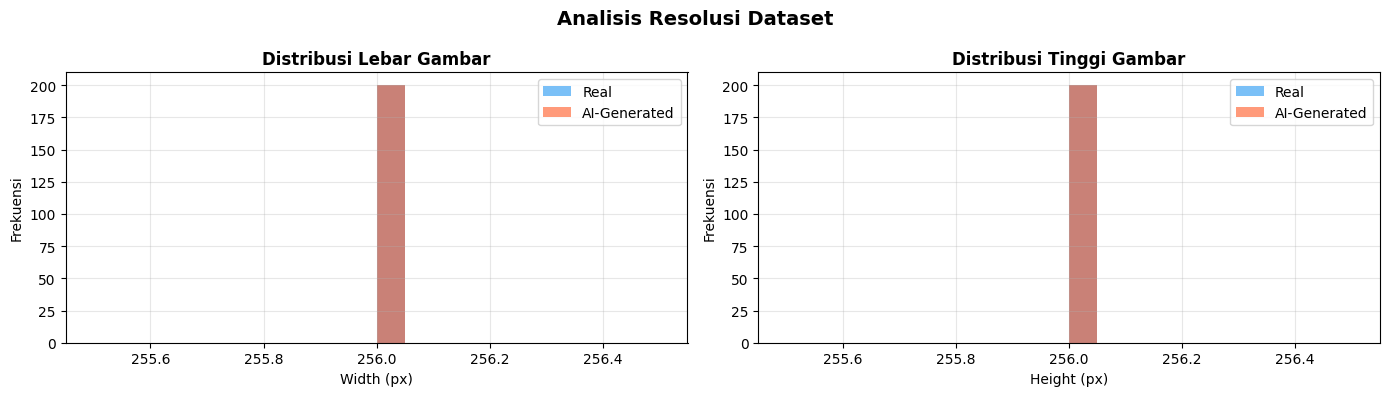

Real  - Width: mean=256px, Height: mean=256px
AI    - Width: mean=256px, Height: mean=256px


In [6]:
# Analisis resolusi gambar (sampel 200 per kelas)
def get_sizes(paths, n=200):
    widths, heights = [], []
    for p in random.sample(list(paths), min(n, len(paths))):
        try:
            w, h = Image.open(p).size
            widths.append(w)
            heights.append(h)
        except:
            pass
    return widths, heights

real_w, real_h = get_sizes(real_paths)
ai_w, ai_h     = get_sizes(ai_paths)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(real_w, bins=20, alpha=0.6, label='Real', color='#2196F3')
axes[0].hist(ai_w,   bins=20, alpha=0.6, label='AI-Generated', color='#FF5722')
axes[0].set_title('Distribusi Lebar Gambar', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Width (px)')
axes[0].set_ylabel('Frekuensi')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(real_h, bins=20, alpha=0.6, label='Real', color='#2196F3')
axes[1].hist(ai_h,   bins=20, alpha=0.6, label='AI-Generated', color='#FF5722')
axes[1].set_title('Distribusi Tinggi Gambar', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Height (px)')
axes[1].set_ylabel('Frekuensi')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Analisis Resolusi Dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/eda_resolusi.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Real  - Width: mean={np.mean(real_w):.0f}px, Height: mean={np.mean(real_h):.0f}px')
print(f'AI    - Width: mean={np.mean(ai_w):.0f}px, Height: mean={np.mean(ai_h):.0f}px')

## 4. Pembagian Dataset & Preprocessing

In [7]:
# Split: 70% Train | 10% Val | 20% Test (stratified)
idx = np.arange(len(all_paths))

# Pisah test 20% dulu
idx_trainval, idx_test, y_trainval, y_test = train_test_split(
    idx, all_labels, test_size=0.20, stratify=all_labels, random_state=SEED
)

# Dari sisa 80%, ambil val 10% dari total = 12.5% dari trainval
idx_train, idx_val, y_train, y_val = train_test_split(
    idx_trainval, y_trainval, test_size=0.125, stratify=y_trainval, random_state=SEED
)

print('=== Pembagian Dataset ===')
print(f'Train  : {len(idx_train):>5} gambar | AI: {np.sum(y_train==1)} | Real: {np.sum(y_train==0)}')
print(f'Val    : {len(idx_val):>5} gambar | AI: {np.sum(y_val==1)}  | Real: {np.sum(y_val==0)}')
print(f'Test   : {len(idx_test):>5} gambar | AI: {np.sum(y_test==1)} | Real: {np.sum(y_test==0)}')
print(f'Total  : {len(all_paths):>5} gambar')
print(f'Rasio  : Train {len(idx_train)/len(all_paths)*100:.1f}% | '
      f'Val {len(idx_val)/len(all_paths)*100:.1f}% | '
      f'Test {len(idx_test)/len(all_paths)*100:.1f}%')

=== Pembagian Dataset ===
Train  : 10500 gambar | AI: 5250 | Real: 5250
Val    :  1500 gambar | AI: 750  | Real: 750
Test   :  3000 gambar | AI: 1500 | Real: 1500
Total  : 15000 gambar
Rasio  : Train 70.0% | Val 10.0% | Test 20.0%


In [8]:
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.BICUBIC),

    # Augmentasi agar model tidak hafal posisi
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.RandomRotation(degrees=10),

    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_test_transform = transforms.Compose([
    # Gunakan cara resize yang sama persis dengan train
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


print('Transformasi telah didefinisikan:')
print('Train  :', [type(t).__name__ for t in train_transform.transforms])
print('Val/Test:', [type(t).__name__ for t in val_test_transform.transforms])

Transformasi telah didefinisikan:
Train  : ['Resize', 'RandomHorizontalFlip', 'ColorJitter', 'RandomRotation', 'ToTensor', 'Normalize']
Val/Test: ['Resize', 'ToTensor', 'Normalize']


In [9]:
# Custom Dataset
class FaceDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths     = paths
        self.labels    = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            img = Image.open(self.paths[idx]).convert('RGB')
        except Exception:
            img = Image.new('RGB', (224, 224), (0, 0, 0))
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

# Buat dataset dan dataloader
BATCH_SIZE = 64

train_dataset = FaceDataset(all_paths[idx_train], all_labels[idx_train], train_transform)
val_dataset   = FaceDataset(all_paths[idx_val],   all_labels[idx_val],   val_test_transform)
test_dataset  = FaceDataset(all_paths[idx_test],  all_labels[idx_test],  val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=4, pin_memory=True)

print(f'Train batches : {len(train_loader)}')
print(f'Val batches   : {len(val_loader)}')
print(f'Test batches  : {len(test_loader)}')

Train batches : 165
Val batches   : 24
Test batches  : 47


## 5. Inisialisasi Model ViT-Base/16

In [10]:
# Load ViT-Base/16 pretrained ImageNet-21k
model = timm.create_model(
    'vit_base_patch16_224',
    pretrained=True,
    num_classes=2
)

# Ganti classification head untuk binary classification
in_features = model.head.in_features
model.head = nn.Linear(in_features, 2)

model = model.to(DEVICE)

# Hitung parameter
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Arsitektur     : ViT-Base/16')
print(f'Total params   : {total_params:,}')
print(f'Trainable      : {trainable_params:,}')
print(f'Patch size     : 16x16')
print(f'Num patches    : 196 (14x14 grid)')
print(f'Hidden dim     : 768')
print(f'Attention heads: 12')
print(f'Encoder layers : 12')
print(f'Output classes : 2 (Real vs AI-Generated)')

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Arsitektur     : ViT-Base/16
Total params   : 85,800,194
Trainable      : 85,800,194
Patch size     : 16x16
Num patches    : 196 (14x14 grid)
Hidden dim     : 768
Attention heads: 12
Encoder layers : 12
Output classes : 2 (Real vs AI-Generated)


## 6. Konfigurasi Hyperparameter dan Pelatihan Model

In [11]:
# Konfigurasi hyperparameter
LEARNING_RATE = 4e-5
WEIGHT_DECAY  = 0.01
MAX_EPOCHS    = 25
PATIENCE      = 3

optimizer  = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
scheduler  = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS, eta_min=1e-6)

print('=== Konfigurasi Pelatihan ===')
print(f'Optimizer      : AdamW')
print(f'Learning Rate  : {LEARNING_RATE}')
print(f'Weight Decay   : {WEIGHT_DECAY}')
print(f'Batch Size     : {BATCH_SIZE}')
print(f'Max Epochs     : {MAX_EPOCHS}')
print(f'Early Stopping : patience={PATIENCE} (berdasarkan val_loss)')
print(f'Loss Function  : Binary Cross-Entropy (CrossEntropyLoss with 2 classes)')
print(f'LR Scheduler   : CosineAnnealingLR')

=== Konfigurasi Pelatihan ===
Optimizer      : AdamW
Learning Rate  : 4e-05
Weight Decay   : 0.01
Batch Size     : 64
Max Epochs     : 25
Early Stopping : patience=3 (berdasarkan val_loss)
Loss Function  : Binary Cross-Entropy (CrossEntropyLoss with 2 classes)
LR Scheduler   : CosineAnnealingLR


In [12]:
# Training loop
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total


def eval_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
    return total_loss / total, correct / total


# Inisialisasi riwayat
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_loss = float('inf')
patience_counter = 0
BEST_MODEL_PATH = '/kaggle/working/best_vit_model.pth'

print('Memulai pelatihan...')
print('='*70)

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_acc     = eval_epoch(model, val_loader, criterion, DEVICE)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    # Early stopping & checkpoint
    improved = ''
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        improved = ' ✓ (saved)'
    else:
        patience_counter += 1

    print(f'Epoch [{epoch:02d}/{MAX_EPOCHS}] '
          f'Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | '
          f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}'
          f'{improved}')

    if patience_counter >= PATIENCE:
        print(f'\nEarly stopping dipicu pada epoch {epoch}.')
        break

print('\nPelatihan selesai!')
print(f'Best val_loss : {best_val_loss:.4f}')
print(f'Model disimpan: {BEST_MODEL_PATH}')

Memulai pelatihan...
Epoch [01/25] Train Loss: 0.4203 Acc: 0.8530 | Val Loss: 0.3230 Acc: 0.9173 ✓ (saved)
Epoch [02/25] Train Loss: 0.2676 Acc: 0.9612 | Val Loss: 0.2489 Acc: 0.9680 ✓ (saved)
Epoch [03/25] Train Loss: 0.2286 Acc: 0.9846 | Val Loss: 0.2413 Acc: 0.9727 ✓ (saved)
Epoch [04/25] Train Loss: 0.2257 Acc: 0.9854 | Val Loss: 0.2346 Acc: 0.9813 ✓ (saved)
Epoch [05/25] Train Loss: 0.2533 Acc: 0.9691 | Val Loss: 0.2180 Acc: 0.9880 ✓ (saved)
Epoch [06/25] Train Loss: 0.2138 Acc: 0.9916 | Val Loss: 0.2126 Acc: 0.9920 ✓ (saved)
Epoch [07/25] Train Loss: 0.2122 Acc: 0.9923 | Val Loss: 0.2675 Acc: 0.9600
Epoch [08/25] Train Loss: 0.2284 Acc: 0.9823 | Val Loss: 0.2245 Acc: 0.9860
Epoch [09/25] Train Loss: 0.2065 Acc: 0.9960 | Val Loss: 0.2146 Acc: 0.9927

Early stopping dipicu pada epoch 9.

Pelatihan selesai!
Best val_loss : 0.2126
Model disimpan: /kaggle/working/best_vit_model.pth


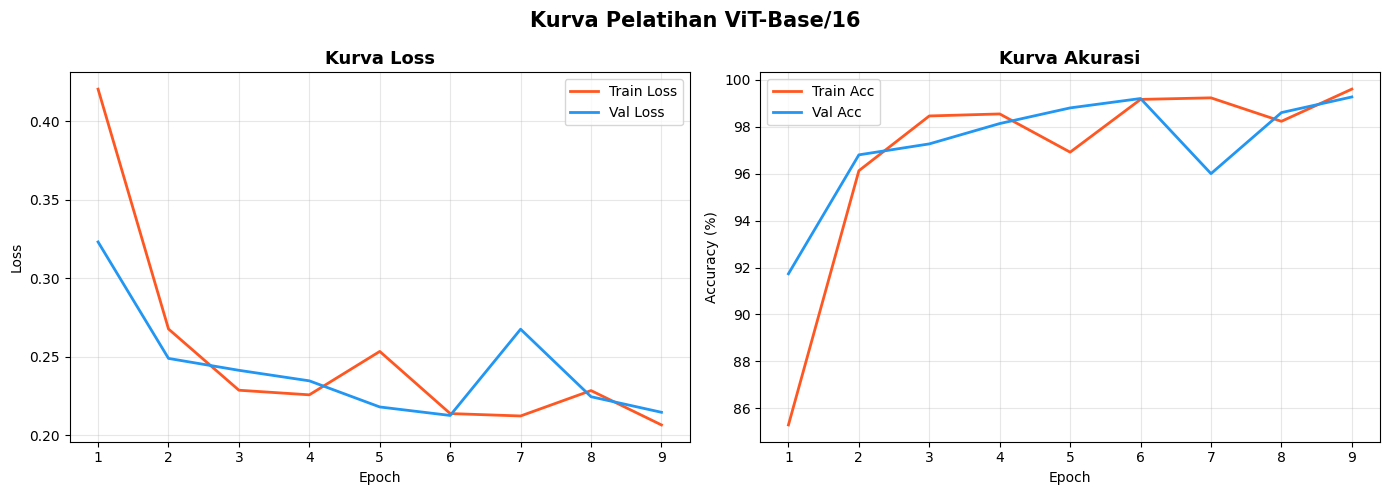

In [13]:
# Plot kurva pelatihan
epochs_ran = len(history['train_loss'])
x = range(1, epochs_ran + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(x, history['train_loss'], label='Train Loss', color='#FF5722', linewidth=2)
axes[0].plot(x, history['val_loss'],   label='Val Loss',   color='#2196F3', linewidth=2)
axes[0].set_title('Kurva Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(x, [a*100 for a in history['train_acc']], label='Train Acc', color='#FF5722', linewidth=2)
axes[1].plot(x, [a*100 for a in history['val_acc']],   label='Val Acc',   color='#2196F3', linewidth=2)
axes[1].set_title('Kurva Akurasi', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Kurva Pelatihan ViT-Base/16', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Evaluasi Model

In [14]:
# Load best model
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
model.eval()

# Inferensi pada test set
all_preds, all_probs, all_true = [], [], []

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc='Evaluasi Test Set'):
        imgs = imgs.to(DEVICE)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_probs.extend(probs)
        all_true.extend(labels.numpy())

all_preds = np.array(all_preds)
all_probs = np.array(all_probs)
all_true  = np.array(all_true)

# Hitung semua metrik
acc  = accuracy_score(all_true, all_preds)
prec = precision_score(all_true, all_preds)
rec  = recall_score(all_true, all_preds)
f1   = f1_score(all_true, all_preds)
auc  = roc_auc_score(all_true, all_probs)

print('='*50)
print('      HASIL EVALUASI MODEL (Test Set)')
print('='*50)
print(f'  Accuracy   : {acc:.4f}  ({acc*100:.2f}%)')
print(f'  Precision  : {prec:.4f}  ({prec*100:.2f}%)')
print(f'  Recall     : {rec:.4f}  ({rec*100:.2f}%)')
print(f'  F1-Score   : {f1:.4f}  ({f1*100:.2f}%)')
print(f'  AUC-ROC    : {auc:.4f}  ({auc*100:.2f}%)')
print('='*50)
print()
print(classification_report(all_true, all_preds,
                             target_names=['Real (0)', 'AI-Generated (1)']))

Evaluasi Test Set:   0%|          | 0/47 [00:00<?, ?it/s]

      HASIL EVALUASI MODEL (Test Set)
  Accuracy   : 0.9873  (98.73%)
  Precision  : 0.9926  (99.26%)
  Recall     : 0.9820  (98.20%)
  F1-Score   : 0.9873  (98.73%)
  AUC-ROC    : 0.9986  (99.86%)

                  precision    recall  f1-score   support

        Real (0)       0.98      0.99      0.99      1500
AI-Generated (1)       0.99      0.98      0.99      1500

        accuracy                           0.99      3000
       macro avg       0.99      0.99      0.99      3000
    weighted avg       0.99      0.99      0.99      3000



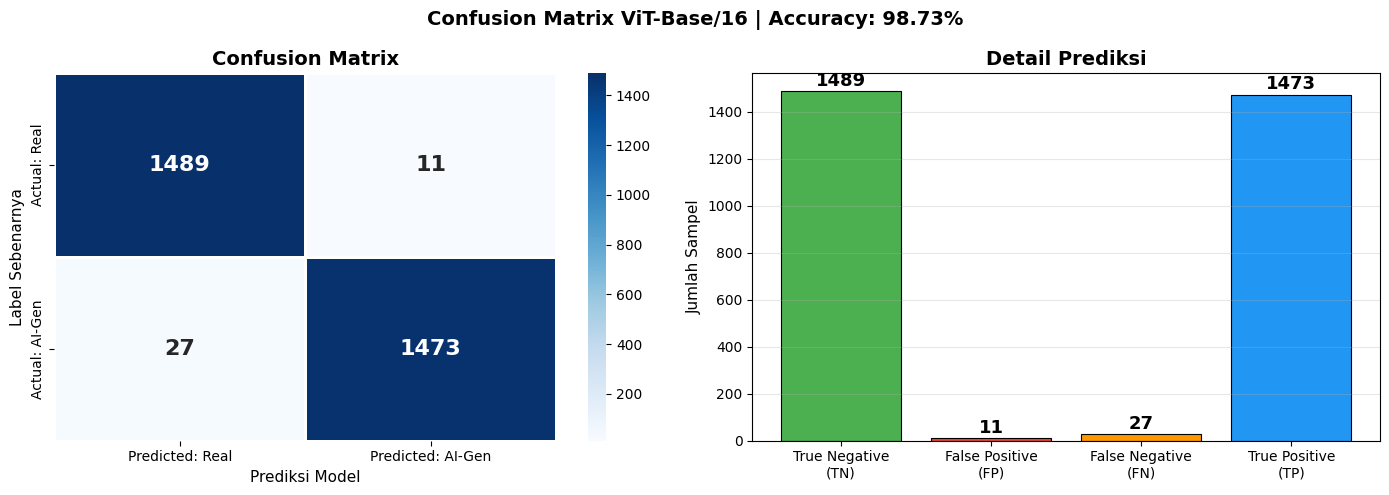

TP=1473 | TN=1489 | FP=11 | FN=27


In [15]:
# Confusion Matrix
cm = confusion_matrix(all_true, all_preds)
TN, FP, FN, TP = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap confusion matrix
cm_df = pd.DataFrame(
    cm, index=['Actual: Real', 'Actual: AI-Gen'],
    columns=['Predicted: Real', 'Predicted: AI-Gen']
)
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues',
            linewidths=2, linecolor='white', ax=axes[0],
            annot_kws={'size': 16, 'fontweight': 'bold'})
axes[0].set_title('Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Label Sebenarnya', fontsize=11)
axes[0].set_xlabel('Prediksi Model', fontsize=11)

# Detail TP/TN/FP/FN
labels_cm = ['True Negative\n(TN)', 'False Positive\n(FP)',
             'False Negative\n(FN)', 'True Positive\n(TP)']
values_cm = [TN, FP, FN, TP]
colors_cm = ['#4CAF50', '#F44336', '#FF9800', '#2196F3']
bars = axes[1].bar(labels_cm, values_cm, color=colors_cm, edgecolor='black', linewidth=0.8)
for bar, val in zip(bars, values_cm):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(val), ha='center', va='bottom', fontsize=13, fontweight='bold')
axes[1].set_title('Detail Prediksi', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Jumlah Sampel', fontsize=11)
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle(f'Confusion Matrix ViT-Base/16 | Accuracy: {acc*100:.2f}%',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'TP={TP} | TN={TN} | FP={FP} | FN={FN}')

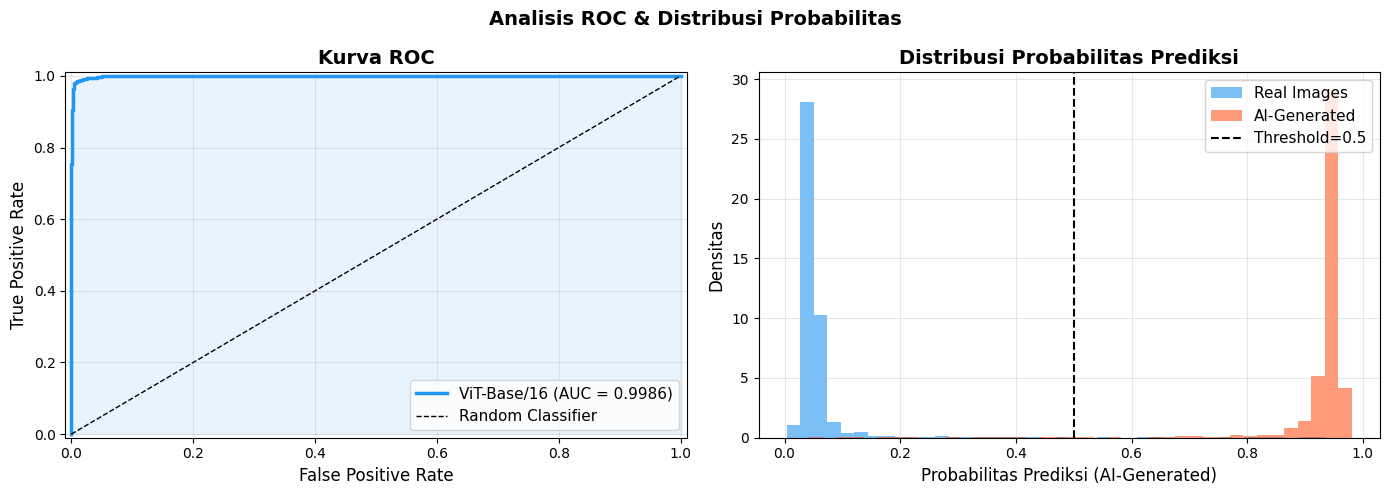

In [16]:
# Kurva ROC
fpr, tpr, thresholds = roc_curve(all_true, all_probs)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
axes[0].plot(fpr, tpr, color='#2196F3', linewidth=2.5, label=f'ViT-Base/16 (AUC = {auc:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
axes[0].fill_between(fpr, tpr, alpha=0.1, color='#2196F3')
axes[0].set_xlabel('False Positive Rate', fontsize=12)
axes[0].set_ylabel('True Positive Rate', fontsize=12)
axes[0].set_title('Kurva ROC', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)
axes[0].set_xlim([-0.01, 1.01])
axes[0].set_ylim([-0.01, 1.01])

# Distribusi probabilitas prediksi
prob_real = all_probs[all_true == 0]
prob_ai   = all_probs[all_true == 1]
axes[1].hist(prob_real, bins=40, alpha=0.6, color='#2196F3', label='Real Images', density=True)
axes[1].hist(prob_ai,   bins=40, alpha=0.6, color='#FF5722', label='AI-Generated', density=True)
axes[1].axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='Threshold=0.5')
axes[1].set_xlabel('Probabilitas Prediksi (AI-Generated)', fontsize=12)
axes[1].set_ylabel('Densitas', fontsize=12)
axes[1].set_title('Distribusi Probabilitas Prediksi', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

plt.suptitle('Analisis ROC & Distribusi Probabilitas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
# Ringkasan metrik per kelas
from sklearn.metrics import precision_recall_fscore_support

p_per, r_per, f_per, s_per = precision_recall_fscore_support(all_true, all_preds)

metrics_df = pd.DataFrame({
    'Kelas':     ['Real (0)', 'AI-Generated (1)'],
    'Precision': [f'{p_per[0]*100:.2f}%', f'{p_per[1]*100:.2f}%'],
    'Recall':    [f'{r_per[0]*100:.2f}%', f'{r_per[1]*100:.2f}%'],
    'F1-Score':  [f'{f_per[0]*100:.2f}%', f'{f_per[1]*100:.2f}%'],
    'Support':   [s_per[0], s_per[1]]
})
print('\nMetrik Per Kelas:')
print(metrics_df.to_string(index=False))

# Simpan ke CSV
summary_df = pd.DataFrame({
    'Metric':  ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC'],
    'Value':   [acc, prec, rec, f1, auc],
    'Percent': [f'{v*100:.2f}%' for v in [acc, prec, rec, f1, auc]]
})
summary_df.to_csv('/kaggle/working/evaluation_results.csv', index=False)
print('\nHasil evaluasi disimpan ke /kaggle/working/evaluation_results.csv')


Metrik Per Kelas:
           Kelas Precision Recall F1-Score  Support
        Real (0)    98.22% 99.27%   98.74%     1500
AI-Generated (1)    99.26% 98.20%   98.73%     1500

Hasil evaluasi disimpan ke /kaggle/working/evaluation_results.csv


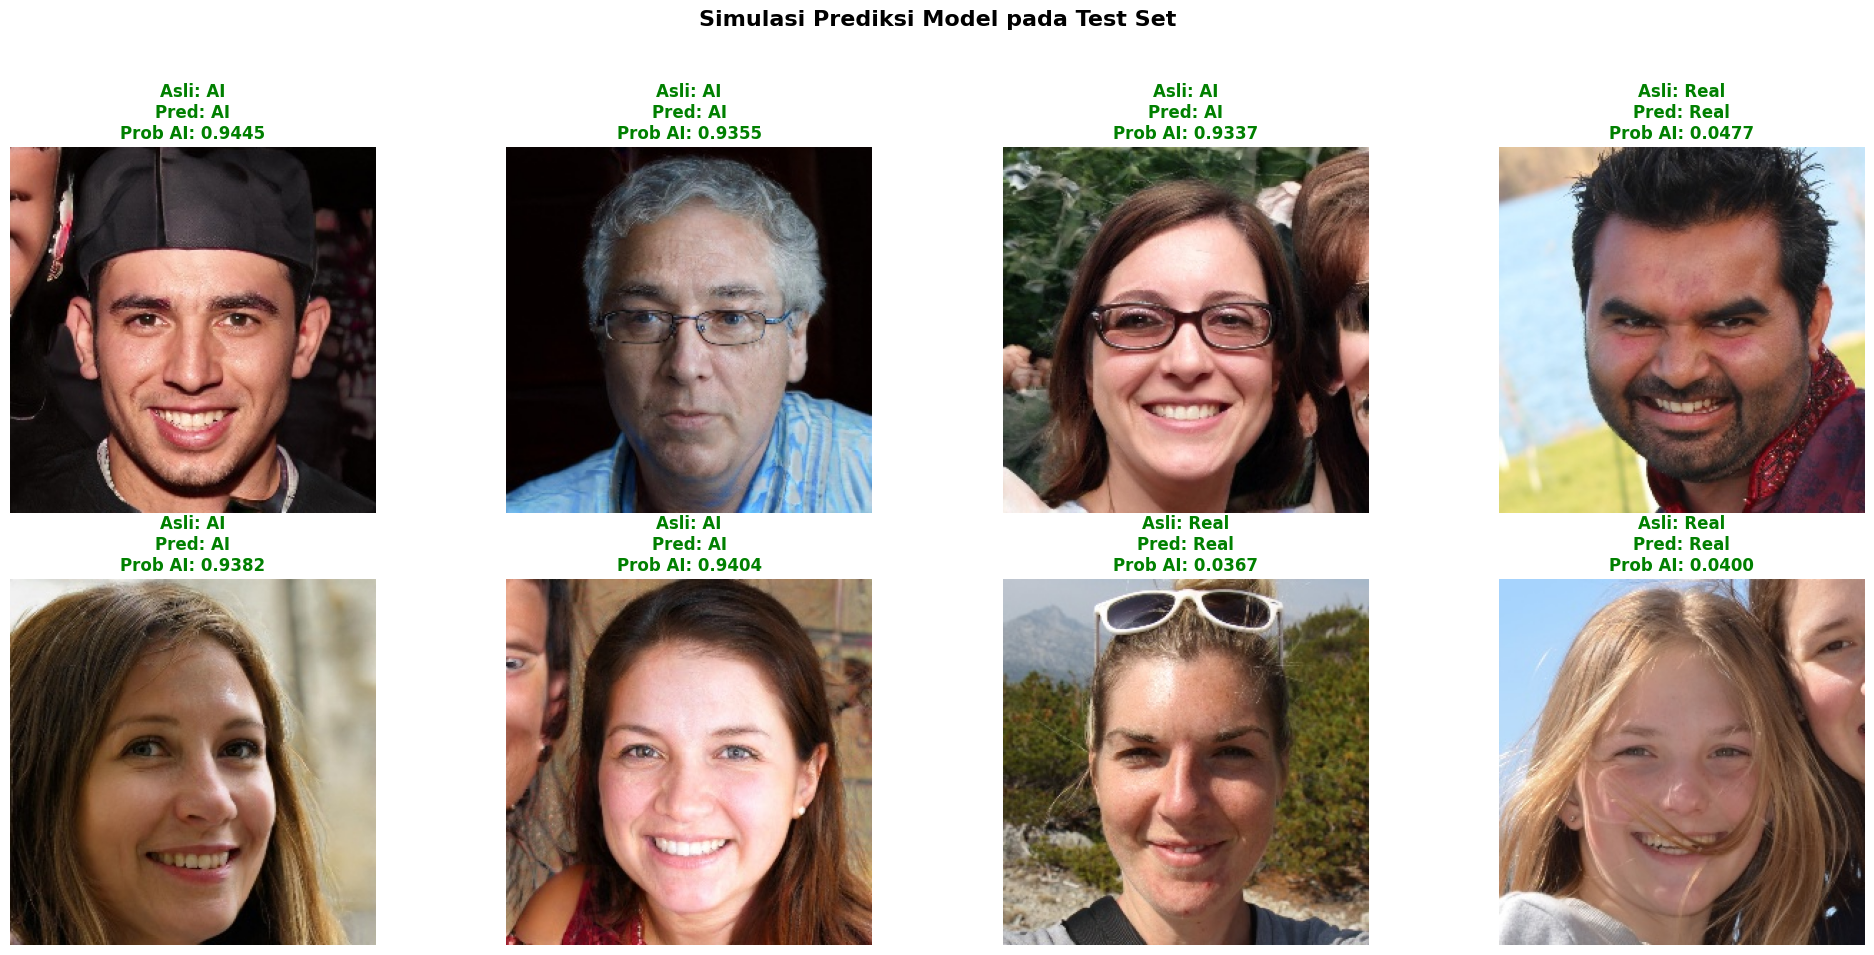

In [18]:
def visualize_results(model, dataset, n_samples=8):
    model.eval()
    indices = random.sample(range(len(dataset)), n_samples)
    
    plt.figure(figsize=(20, 10))
    for i, idx in enumerate(indices):
        path, label = dataset.paths[idx], dataset.labels[idx]
        img_pil = Image.open(path).convert('RGB')
        
        # Transformasi untuk model
        img_tensor = val_test_transform(img_pil).unsqueeze(0).to(DEVICE)
        
        with torch.no_grad():
            output = model(img_tensor)
            prob = torch.softmax(output, dim=1)[0, 1].item()
            pred = output.argmax(dim=1).item()
        
        # Penentuan warna teks: Hijau jika benar, Merah jika salah
        is_correct = (pred == label)
        color = 'green' if is_correct else 'red'
        
        plt.subplot(2, 4, i+1)
        plt.imshow(img_pil)
        plt.title(f"Asli: {'AI' if label==1 else 'Real'}\nPred: {'AI' if pred==1 else 'Real'}\nProb AI: {prob:.4f}", 
                  color=color, fontsize=12, fontweight='bold')
        plt.axis('off')
    
    plt.suptitle("Simulasi Prediksi Model pada Test Set", fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Panggil fungsi visualisasi
visualize_results(model, test_dataset)


## 8. Baseline Comparison: ResNet-50 vs EfficientNet-B0 vs ViT-Base/16

In [19]:
from torchvision import models
def train_and_evaluate_model(model_name, model_obj, train_loader, val_loader, test_loader,
                              device, save_path):
    """Train and evaluate a given model. Returns metrics dict."""
    print(f'\n{'='*60}')
    print(f'Training: {model_name}')
    print(f'{'='*60}')

    model_obj = model_obj.to(device)
    opt = optim.AdamW(model_obj.parameters(), lr=4e-5, weight_decay=0.01)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=25, eta_min=1e-6)

    best_val_loss = float('inf')
    patience_counter = 0
    PATIENCE = 3

    for epoch in range(1, 26):
        # Train
        model_obj.train()
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            opt.zero_grad()
            outputs = model_obj(imgs)
            loss = crit(outputs, labels)
            loss.backward()
            opt.step()

        # Validate
        model_obj.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model_obj(imgs)
                loss = crit(outputs, labels)
                val_loss += loss.item() * imgs.size(0)
                preds = outputs.argmax(dim=1)
                val_correct += (preds == labels).sum().item()
                val_total += imgs.size(0)
        val_loss /= val_total
        val_acc   = val_correct / val_total
        sched.step()

        improved = ''
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save(model_obj.state_dict(), save_path)
            improved = ' ✓'
        else:
            patience_counter += 1

        print(f'  Epoch [{epoch:02d}] Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}{improved}')

        if patience_counter >= PATIENCE:
            print(f'  Early stopping at epoch {epoch}.')
            break

    # Load best and evaluate on test
    model_obj.load_state_dict(torch.load(save_path, map_location=device))
    model_obj.eval()
    preds_all, probs_all, true_all = [], [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(device)
            outputs = model_obj(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()
            preds = outputs.argmax(dim=1).cpu().numpy()
            preds_all.extend(preds)
            probs_all.extend(probs)
            true_all.extend(labels.numpy())

    preds_all = np.array(preds_all)
    probs_all = np.array(probs_all)
    true_all  = np.array(true_all)

    metrics = {
        'model':     model_name,
        'accuracy':  accuracy_score(true_all, preds_all),
        'precision': precision_score(true_all, preds_all),
        'recall':    recall_score(true_all, preds_all),
        'f1':        f1_score(true_all, preds_all),
        'auc':       roc_auc_score(true_all, probs_all),
        'fpr':       roc_curve(true_all, probs_all)[0],
        'tpr':       roc_curve(true_all, probs_all)[1],
    }
    print(f'\n  Test Results → Acc: {metrics["accuracy"]*100:.2f}% | '
          f'F1: {metrics["f1"]*100:.2f}% | AUC: {metrics["auc"]*100:.2f}%')
    return metrics


# --- ResNet-50 ---
resnet = models.resnet50(pretrained=True)
resnet.fc = nn.Linear(resnet.fc.in_features, 2)
metrics_resnet = train_and_evaluate_model(
    'ResNet-50', resnet, train_loader, val_loader, test_loader,
    DEVICE, '/kaggle/working/best_resnet50.pth'
)

# --- EfficientNet-B0 ---
efficientnet = timm.create_model('efficientnet_b0', pretrained=True, num_classes=2)
metrics_effnet = train_and_evaluate_model(
    'EfficientNet-B0', efficientnet, train_loader, val_loader, test_loader,
    DEVICE, '/kaggle/working/best_efficientnet_b0.pth'
)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 178MB/s]



Training: ResNet-50
  Epoch [01] Val Loss: 0.2984 | Val Acc: 0.9460 ✓
  Epoch [02] Val Loss: 0.2842 | Val Acc: 0.9540 ✓
  Epoch [03] Val Loss: 0.2408 | Val Acc: 0.9827 ✓
  Epoch [04] Val Loss: 0.2388 | Val Acc: 0.9813 ✓
  Epoch [05] Val Loss: 0.2324 | Val Acc: 0.9907 ✓
  Epoch [06] Val Loss: 0.2335 | Val Acc: 0.9833
  Epoch [07] Val Loss: 0.2335 | Val Acc: 0.9820
  Epoch [08] Val Loss: 0.2436 | Val Acc: 0.9773
  Early stopping at epoch 8.

  Test Results → Acc: 98.33% | F1: 98.33% | AUC: 99.88%


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]


Training: EfficientNet-B0
  Epoch [01] Val Loss: 0.9271 | Val Acc: 0.7627 ✓
  Epoch [02] Val Loss: 0.7445 | Val Acc: 0.8147 ✓
  Epoch [03] Val Loss: 0.6895 | Val Acc: 0.8113 ✓
  Epoch [04] Val Loss: 0.6479 | Val Acc: 0.8380 ✓
  Epoch [05] Val Loss: 0.6093 | Val Acc: 0.8500 ✓
  Epoch [06] Val Loss: 0.5884 | Val Acc: 0.8553 ✓
  Epoch [07] Val Loss: 0.5632 | Val Acc: 0.8500 ✓
  Epoch [08] Val Loss: 0.5445 | Val Acc: 0.8620 ✓
  Epoch [09] Val Loss: 0.5352 | Val Acc: 0.8580 ✓
  Epoch [10] Val Loss: 0.5148 | Val Acc: 0.8693 ✓
  Epoch [11] Val Loss: 0.5126 | Val Acc: 0.8593 ✓
  Epoch [12] Val Loss: 0.4960 | Val Acc: 0.8600 ✓
  Epoch [13] Val Loss: 0.4870 | Val Acc: 0.8720 ✓
  Epoch [14] Val Loss: 0.4674 | Val Acc: 0.8747 ✓
  Epoch [15] Val Loss: 0.4689 | Val Acc: 0.8680
  Epoch [16] Val Loss: 0.4720 | Val Acc: 0.8727
  Epoch [17] Val Loss: 0.4553 | Val Acc: 0.8780 ✓
  Epoch [18] Val Loss: 0.4491 | Val Acc: 0.8833 ✓
  Epoch [19] Val Loss: 0.4580 | Val Acc: 0.8747
  Epoch [20] Val Loss: 0.4490


   COMPARATIVE RESULTS: ViT-Base/16 vs CNN Baselines
Model                       Accuracy  Precision     Recall   F1-Score    AUC-ROC
--------------------------------------------------------------------------------
ResNet-50                     98.33%     98.40%     98.27%     98.33%     99.88%
EfficientNet-B0               88.23%     87.76%     88.87%     88.31%     95.17%
ViT-Base/16 (Ours)            98.73%     99.26%     98.20%     98.73%     99.86%


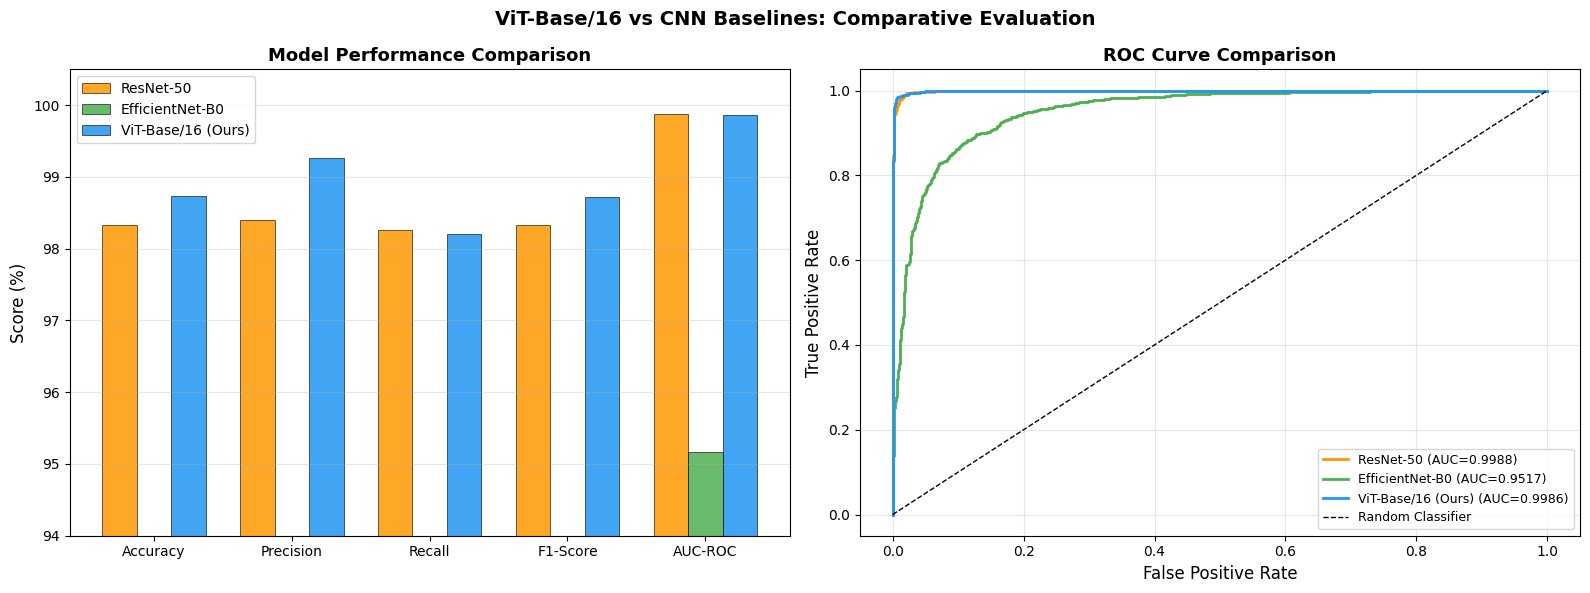

In [20]:
# Collect ViT metrics alongside baselines
vit_fpr, vit_tpr, _ = roc_curve(all_true, all_probs)
metrics_vit = {
    'model': 'ViT-Base/16 (Ours)',
    'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1, 'auc': auc,
    'fpr': vit_fpr, 'tpr': vit_tpr
}

all_metrics = [metrics_resnet, metrics_effnet, metrics_vit]

# --- Comparison Table ---
print('\n' + '='*80)
print('   COMPARATIVE RESULTS: ViT-Base/16 vs CNN Baselines')
print('='*80)
print(f'{"Model":<25} {"Accuracy":>10} {"Precision":>10} {"Recall":>10} {"F1-Score":>10} {"AUC-ROC":>10}')
print('-'*80)
for m in all_metrics:
    print(f'{m["model"]:<25} '
          f'{m["accuracy"]*100:>9.2f}% '
          f'{m["precision"]*100:>9.2f}% '
          f'{m["recall"]*100:>9.2f}% '
          f'{m["f1"]*100:>9.2f}% '
          f'{m["auc"]*100:>9.2f}%')
print('='*80)

# --- Comparison Bar Chart ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

model_names = [m['model'] for m in all_metrics]
metric_keys = ['accuracy', 'precision', 'recall', 'f1', 'auc']
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
colors_bar = ['#FF9800', '#4CAF50', '#2196F3']

x_pos = np.arange(len(metric_labels))
width = 0.25

for i, (m, color) in enumerate(zip(all_metrics, colors_bar)):
    vals = [m[k]*100 for k in metric_keys]
    bars = axes[0].bar(x_pos + i*width, vals, width,
                       label=m['model'], color=color, alpha=0.85, edgecolor='black', linewidth=0.5)

axes[0].set_xticks(x_pos + width)
axes[0].set_xticklabels(metric_labels, fontsize=10)
axes[0].set_ylabel('Score (%)', fontsize=12)
axes[0].set_title('Model Performance Comparison', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].set_ylim([94, 100.5])
axes[0].grid(axis='y', alpha=0.3)

# ROC Comparison
colors_roc = ['#FF9800', '#4CAF50', '#2196F3']
for m, color in zip(all_metrics, colors_roc):
    axes[1].plot(m['fpr'], m['tpr'], linewidth=2,
                 label=f'{m["model"]} (AUC={m["auc"]:.4f})', color=color)
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate', fontsize=12)
axes[1].set_title('ROC Curve Comparison', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.suptitle('ViT-Base/16 vs CNN Baselines: Comparative Evaluation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/baseline_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Robustness Testing

In [21]:
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))

def evaluate_robustness(model, paths, labels, device, perturbation_fn,
                        transform=None, desc=''):
    """Evaluasi model pada data yang dimodifikasi."""
    if transform is None:
        transform = val_test_transform

    model.eval()
    preds_all, true_all, probs_all = [], [], []

    for path, label in zip(paths, labels):
        try:
            img = Image.open(path).convert('RGB')
            img = perturbation_fn(img)  # Terapkan modifikasi
            tensor = transform(img).unsqueeze(0).to(device)
            with torch.no_grad():
                out  = model(tensor)
                prob = torch.softmax(out, dim=1)[0, 1].item()
                pred = out.argmax(dim=1).item()
            preds_all.append(pred)
            probs_all.append(prob)
            true_all.append(label)
        except:
            pass

    acc_r = accuracy_score(true_all, preds_all)
    f1_r  = f1_score(true_all, preds_all, zero_division=0)
    auc_r = roc_auc_score(true_all, probs_all) if len(set(true_all)) > 1 else 0.0
    return acc_r, f1_r, auc_r


# Sampel 300 gambar dari test set untuk robustness (lebih cepat)
rob_idx = np.random.choice(len(idx_test), size=min(300, len(idx_test)), replace=False)
rob_paths  = all_paths[idx_test][rob_idx]
rob_labels = all_labels[idx_test][rob_idx]

print(f'Robustness testing pada {len(rob_paths)} gambar sampel...')

Robustness testing pada 300 gambar sampel...


In [22]:
# 9.1 JPEG Compression
jpeg_results = {}
jpeg_qualities = [90, 70, 50, 30, 10]

print('=== JPEG Compression Robustness ===')
for q in jpeg_qualities:
    def jpeg_fn(img, quality=q):
        buf = io.BytesIO()
        img.save(buf, format='JPEG', quality=quality)
        buf.seek(0)
        return Image.open(buf).convert('RGB')

    acc_r, f1_r, auc_r = evaluate_robustness(
        model, rob_paths, rob_labels, DEVICE, jpeg_fn,
        desc=f'JPEG Q={q}'
    )
    jpeg_results[q] = {'accuracy': acc_r, 'f1': f1_r, 'auc': auc_r}
    print(f'  Quality={q:3d} | Acc={acc_r:.4f} | F1={f1_r:.4f} | AUC={auc_r:.4f}')

print()

=== JPEG Compression Robustness ===
  Quality= 90 | Acc=0.9867 | F1=0.9861 | AUC=0.9982
  Quality= 70 | Acc=0.9800 | F1=0.9793 | AUC=0.9917
  Quality= 50 | Acc=0.9533 | F1=0.9530 | AUC=0.9902
  Quality= 30 | Acc=0.9467 | F1=0.9467 | AUC=0.9877
  Quality= 10 | Acc=0.9067 | F1=0.9041 | AUC=0.9587



In [23]:
# 9.2 Resolution Variation
res_results = {}
resolutions = [192, 128, 96, 64]

print('=== Resolution Variation Robustness ===')
for res in resolutions:
    def res_fn(img, r=res):
        return img.resize((r, r), Image.BILINEAR)

    acc_r, f1_r, auc_r = evaluate_robustness(
        model, rob_paths, rob_labels, DEVICE, res_fn,
        desc=f'Res={res}'
    )
    res_results[res] = {'accuracy': acc_r, 'f1': f1_r, 'auc': auc_r}
    print(f'  Resolution={res:3d}x{res:<3d} | Acc={acc_r:.4f} | F1={f1_r:.4f} | AUC={auc_r:.4f}')

print()

=== Resolution Variation Robustness ===
  Resolution=192x192 | Acc=0.9933 | F1=0.9930 | AUC=0.9980
  Resolution=128x128 | Acc=0.9833 | F1=0.9825 | AUC=0.9957
  Resolution= 96x96  | Acc=0.9800 | F1=0.9790 | AUC=0.9934
  Resolution= 64x64  | Acc=0.9700 | F1=0.9689 | AUC=0.9855



In [24]:
# 9.3 Gaussian Noise Addition
noise_results = {}
noise_levels = [0.01, 0.03, 0.05, 0.10, 0.20]

print('=== Gaussian Noise Robustness ===')
for sigma in noise_levels:
    def noise_fn(img, s=sigma):
        arr = np.array(img).astype(np.float32) / 255.0
        noisy = arr + np.random.normal(0, s, arr.shape)
        noisy = np.clip(noisy, 0, 1)
        return Image.fromarray((noisy * 255).astype(np.uint8))

    acc_r, f1_r, auc_r = evaluate_robustness(
        model, rob_paths, rob_labels, DEVICE, noise_fn,
        desc=f'Noise σ={sigma}'
    )
    noise_results[sigma] = {'accuracy': acc_r, 'f1': f1_r, 'auc': auc_r}
    print(f'  Sigma={sigma:.2f} | Acc={acc_r:.4f} | F1={f1_r:.4f} | AUC={auc_r:.4f}')

=== Gaussian Noise Robustness ===
  Sigma=0.01 | Acc=0.9900 | F1=0.9895 | AUC=0.9986
  Sigma=0.03 | Acc=0.9700 | F1=0.9693 | AUC=0.9909
  Sigma=0.05 | Acc=0.9333 | F1=0.9338 | AUC=0.9858
  Sigma=0.10 | Acc=0.8567 | F1=0.8677 | AUC=0.9689
  Sigma=0.20 | Acc=0.7667 | F1=0.8000 | AUC=0.9234


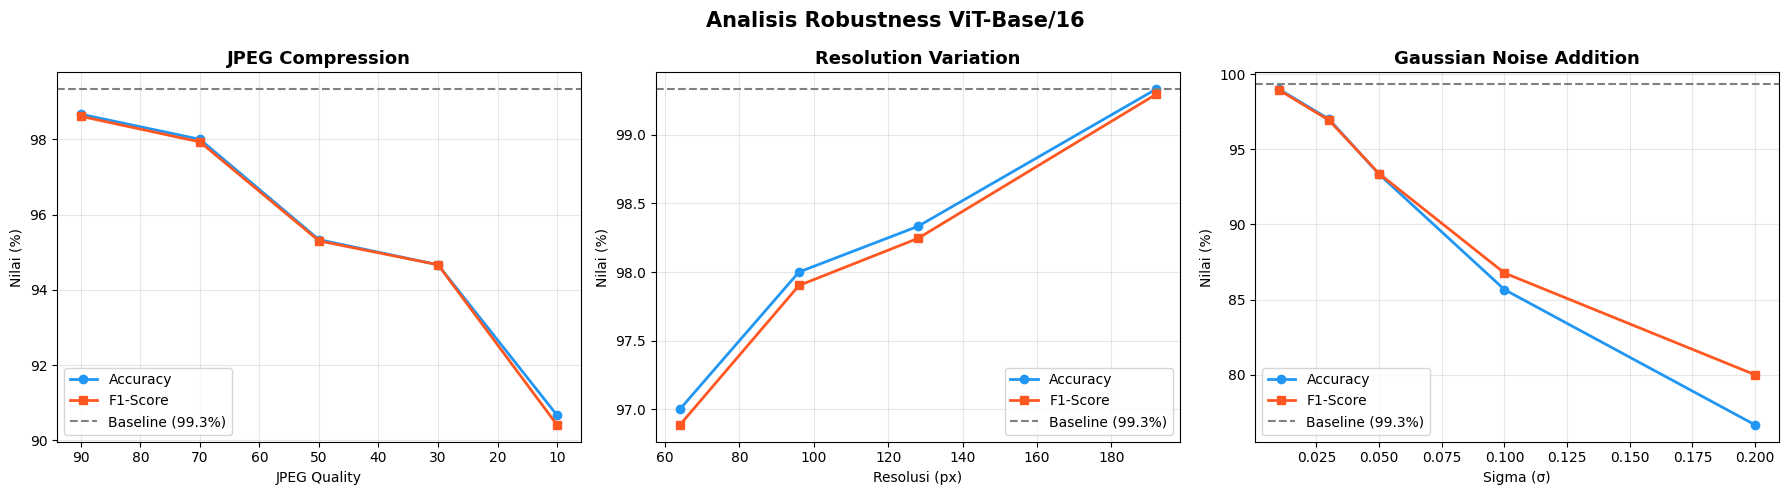

In [25]:
# Baseline (tanpa modifikasi)
baseline_fn = lambda img: img
acc_base, f1_base, auc_base = evaluate_robustness(
    model, rob_paths, rob_labels, DEVICE, baseline_fn
)

# Visualisasi robustness
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# JPEG
q_vals   = sorted(jpeg_results.keys(), reverse=True)
acc_jpeg = [jpeg_results[q]['accuracy'] for q in q_vals]
f1_jpeg  = [jpeg_results[q]['f1']       for q in q_vals]
axes[0].plot(q_vals, [a*100 for a in acc_jpeg], 'o-', label='Accuracy', color='#2196F3', linewidth=2)
axes[0].plot(q_vals, [f*100 for f in f1_jpeg],  's-', label='F1-Score', color='#FF5722', linewidth=2)
axes[0].axhline(acc_base*100, color='gray', linestyle='--', label=f'Baseline ({acc_base*100:.1f}%)')
axes[0].set_title('JPEG Compression', fontsize=13, fontweight='bold')
axes[0].set_xlabel('JPEG Quality')
axes[0].set_ylabel('Nilai (%)')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].invert_xaxis()

# Resolution
r_vals   = sorted(res_results.keys(), reverse=True)
acc_res  = [res_results[r]['accuracy'] for r in r_vals]
f1_res   = [res_results[r]['f1']       for r in r_vals]
axes[1].plot(r_vals, [a*100 for a in acc_res], 'o-', label='Accuracy', color='#2196F3', linewidth=2)
axes[1].plot(r_vals, [f*100 for f in f1_res],  's-', label='F1-Score', color='#FF5722', linewidth=2)
axes[1].axhline(acc_base*100, color='gray', linestyle='--', label=f'Baseline ({acc_base*100:.1f}%)')
axes[1].set_title('Resolution Variation', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Resolusi (px)')
axes[1].set_ylabel('Nilai (%)')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Noise
n_vals   = sorted(noise_results.keys())
acc_noi  = [noise_results[n]['accuracy'] for n in n_vals]
f1_noi   = [noise_results[n]['f1']       for n in n_vals]
axes[2].plot(n_vals, [a*100 for a in acc_noi], 'o-', label='Accuracy', color='#2196F3', linewidth=2)
axes[2].plot(n_vals, [f*100 for f in f1_noi],  's-', label='F1-Score', color='#FF5722', linewidth=2)
axes[2].axhline(acc_base*100, color='gray', linestyle='--', label=f'Baseline ({acc_base*100:.1f}%)')
axes[2].set_title('Gaussian Noise Addition', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Sigma (σ)')
axes[2].set_ylabel('Nilai (%)')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('Analisis Robustness ViT-Base/16', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/robustness_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Visualisasi Attention Rollout

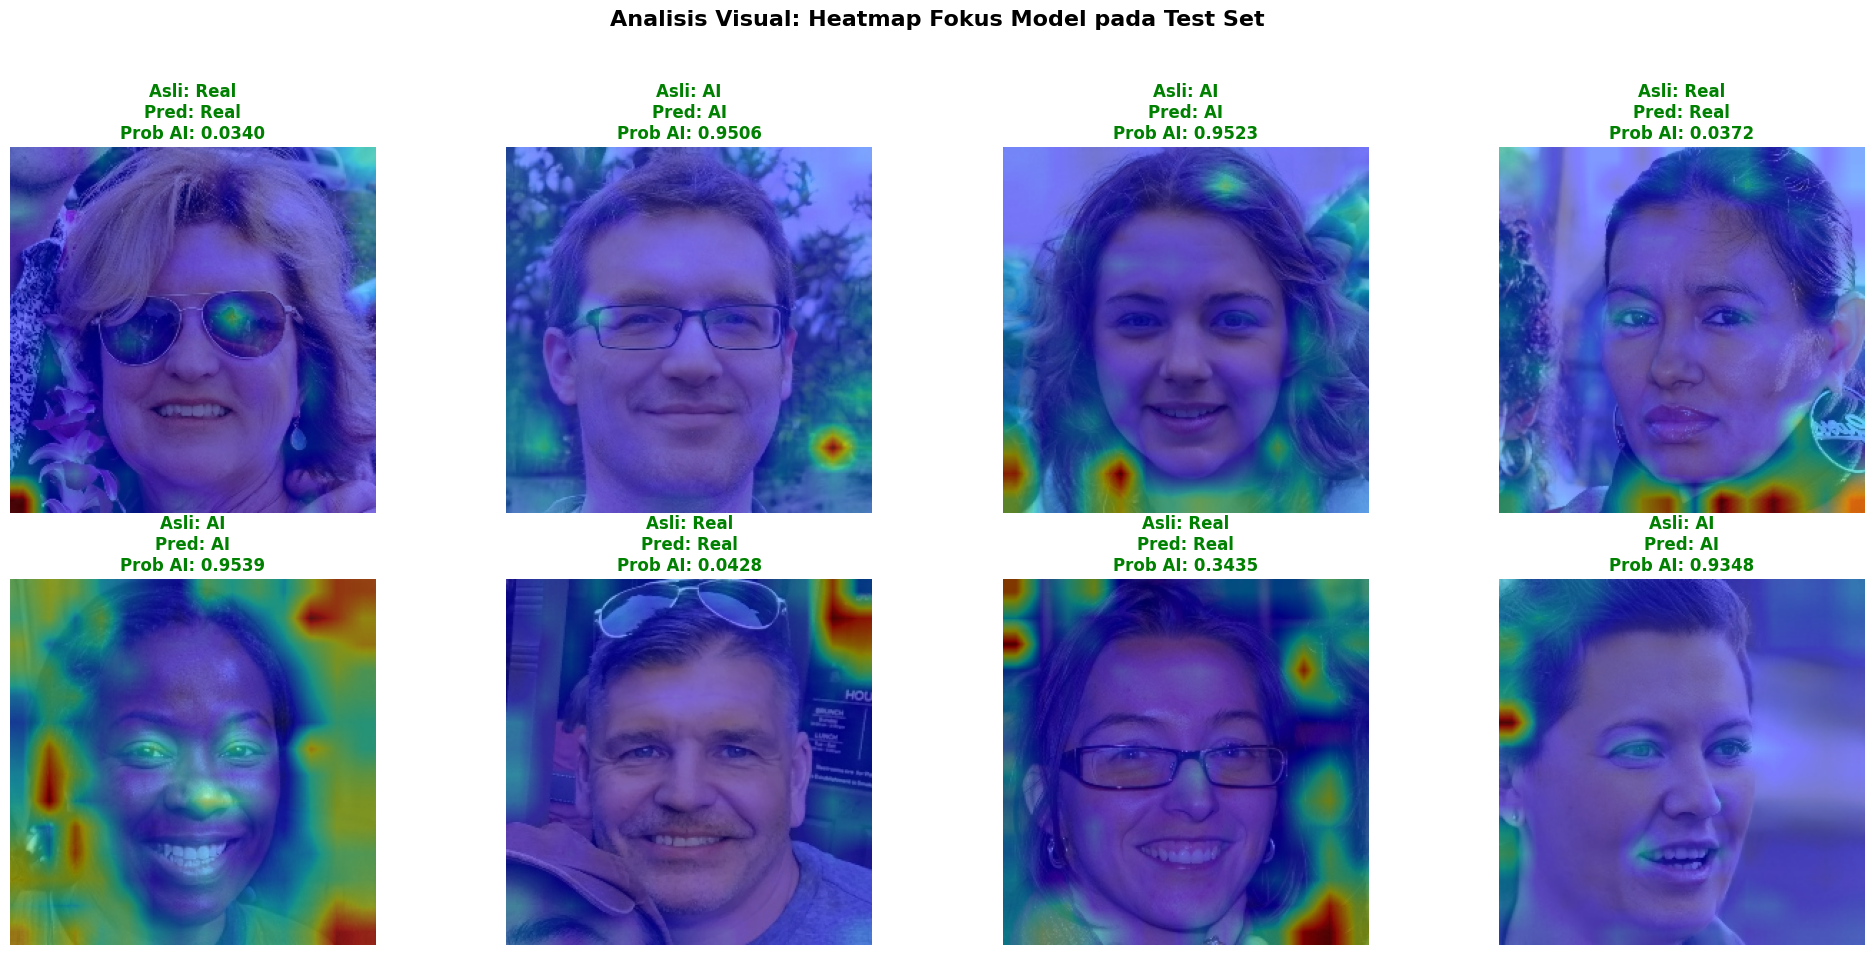

In [26]:
for block in model.blocks:
    block.attn.fused_attn = False

class AttentionRollout:
    def __init__(self, model):
        self.model = model
        self.attentions = []
        self._hooks = []
        self._register_hooks()

    def _register_hooks(self):
        def hook(module, input, output):
            self.attentions.append(output.detach().cpu())
        for block in self.model.blocks:
            h = block.attn.attn_drop.register_forward_hook(hook)
            self._hooks.append(h)

    def __call__(self, img_tensor):
        self.attentions = []
        self.model.eval()
        with torch.no_grad():
            _ = self.model(img_tensor)
        
        # Kalkulasi Rollout
        num_tokens = self.attentions[0].size(-1)
        result = torch.eye(num_tokens)
        for attn in self.attentions:
            attn_mean = attn[0].mean(dim=0)
            attn_mean = attn_mean + torch.eye(num_tokens)
            attn_mean = attn_mean / attn_mean.sum(dim=-1, keepdim=True)
            result = torch.matmul(attn_mean, result)

        mask = result[0, 1:]
        side = int(mask.size(0) ** 0.5)
        mask = mask.reshape(side, side).numpy()
        mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)
        return mask

rollout = AttentionRollout(model)

def visualize_final_results(model, dataset, rollout_fn, n_samples=8):
    model.eval()
    indices = random.sample(range(len(dataset)), n_samples)
    
    plt.figure(figsize=(20, 10))
    for i, idx in enumerate(indices):
        path, label = dataset.paths[idx], dataset.labels[idx]
        img_pil = Image.open(path).convert('RGB')
        img_tensor = val_test_transform(img_pil).unsqueeze(0).to(DEVICE)
        
        # Prediksi
        with torch.no_grad():
            output = model(img_tensor)
            prob = torch.softmax(output, dim=1)[0, 1].item()
            pred = output.argmax(dim=1).item()
            
            # Ambil Attention Map
            mask = rollout_fn(img_tensor)
        
        # Overlay Heatmap
        mask_resized = np.array(Image.fromarray((mask * 255).astype(np.uint8)).resize(img_pil.size, Image.BILINEAR))
        heatmap = plt.cm.jet(mask_resized / 255.0)[:, :, :3]
        overlay = (np.array(img_pil) * 0.5 + (heatmap * 255) * 0.5).astype(np.uint8)
        
        is_correct = (pred == label)
        color = 'green' if is_correct else 'red'
        
        plt.subplot(2, 4, i+1)
        plt.imshow(overlay)
        plt.title(f"Asli: {'AI' if label==1 else 'Real'}\nPred: {'AI' if pred==1 else 'Real'}\nProb AI: {prob:.4f}", 
                  color=color, fontsize=12, fontweight='bold')
        plt.axis('off')
    
    plt.suptitle("Analisis Visual: Heatmap Fokus Model pada Test Set", fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig('/kaggle/working/attention_maps.png', dpi=150)
    plt.show()

visualize_final_results(model, test_dataset, rollout)

## 10. Ringkasan Akhir

In [27]:
print('='*60)
print('       RINGKASAN HASIL PENELITIAN')
print('='*60)
print()
print('>>> Model : ViT-Base/16 (Transfer Learning dari ImageNet-21k)')
print(f'>>> Dataset: {total} gambar ({n_ai} AI-Generated | {n_real} Real Images)')
print()
print('--- Performa pada Test Set ---')
print(f'  Accuracy  : {acc*100:.2f}%')
print(f'  Precision : {prec*100:.2f}%')
print(f'  Recall    : {rec*100:.2f}%')
print(f'  F1-Score  : {f1*100:.2f}%')
print(f'  AUC-ROC   : {auc*100:.2f}%')
print()
print('--- Baseline Comparison ---')
for m in [metrics_resnet, metrics_effnet, metrics_vit]:
    print(f'  {m["model"]:<25}: Acc={m["accuracy"]*100:.2f}% | AUC={m["auc"]*100:.2f}%')
print()
print('--- Robustness ---')
print(f'  Baseline (no aug): Acc={acc_base*100:.2f}%')
print(f'  JPEG Q=10 (agresif): Acc={jpeg_results[10]["accuracy"]*100:.2f}%')
print(f'  Resolusi 64x64     : Acc={res_results[64]["accuracy"]*100:.2f}%')
print(f'  Noise σ=0.20       : Acc={noise_results[0.20]["accuracy"]*100:.2f}%')
print()
print('--- File Tersimpan ---')
files_saved = [
    '/kaggle/working/best_vit_model.pth',
    '/kaggle/working/best_resnet50.pth',
    '/kaggle/working/best_efficientnet_b0.pth',
    '/kaggle/working/evaluation_results.csv',
    '/kaggle/working/training_curves.png',
    '/kaggle/working/confusion_matrix.png',
    '/kaggle/working/roc_curve.png',
    '/kaggle/working/baseline_comparison.png',
    '/kaggle/working/robustness_analysis.png',
    '/kaggle/working/attention_maps.png',
]
for f in files_saved:
    status = '✓' if os.path.exists(f) else '✗'
    print(f'  {status} {f}')
print('='*60)

       RINGKASAN HASIL PENELITIAN

>>> Model : ViT-Base/16 (Transfer Learning dari ImageNet-21k)
>>> Dataset: 15000 gambar (7500 AI-Generated | 7500 Real Images)

--- Performa pada Test Set ---
  Accuracy  : 98.73%
  Precision : 99.26%
  Recall    : 98.20%
  F1-Score  : 98.73%
  AUC-ROC   : 99.86%

--- Baseline Comparison ---
  ResNet-50                : Acc=98.33% | AUC=99.88%
  EfficientNet-B0          : Acc=88.23% | AUC=95.17%
  ViT-Base/16 (Ours)       : Acc=98.73% | AUC=99.86%

--- Robustness ---
  Baseline (no aug): Acc=99.33%
  JPEG Q=10 (agresif): Acc=90.67%
  Resolusi 64x64     : Acc=97.00%
  Noise σ=0.20       : Acc=76.67%

--- File Tersimpan ---
  ✓ /kaggle/working/best_vit_model.pth
  ✓ /kaggle/working/best_resnet50.pth
  ✓ /kaggle/working/best_efficientnet_b0.pth
  ✓ /kaggle/working/evaluation_results.csv
  ✓ /kaggle/working/training_curves.png
  ✓ /kaggle/working/confusion_matrix.png
  ✓ /kaggle/working/roc_curve.png
  ✓ /kaggle/working/baseline_comparison.png
  ✓ /kaggle